# Tarea Práctica 4 - Física Computacional
Integración numérica.



In [6]:
%pip install scipy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## Ejercicio 1: Regla del Trapecio
El archivo velocidades.txt (adjunto), contiene dos columnas de numeros, la primera  ́
representa el tiempo t en segundos y la segunda la x-velocidad en metros por segundo
de una partícula, medida una vez por segundo desde el tiempo t = 0 hasta t = 100.
Las primeras líneas se ven así:...

(a) Lee los datos y, usando la regla del trapecio, calcula a partir de ellos la distancia
aproximada recorrida por la partícula en la dirección x como una función del  tiempo.


In [7]:
import numpy as np
import matplotlib.pyplot as plt

datos = np.loadtxt("velocidades.txt")

tiempo = datos[:, 0]
velocidad = datos[:, 1]

distancia = np.zeros(len(tiempo))

for i in range(1, len(tiempo)):
    dt = tiempo[i] - tiempo[i - 1]
    distancia[i] = distancia[i - 1] + (velocidad[i] + velocidad[i - 1]) * dt / 2

print("Distancia recorrida al final:", distancia[-1], "m")


Distancia recorrida al final: 8.218924000000003 m


(b) Extiende tu programa para hacer una grafica que muestre, en el mismo gráfico, tanto la curva de velocidad original como la distancia recorrida como una función del tiempo.

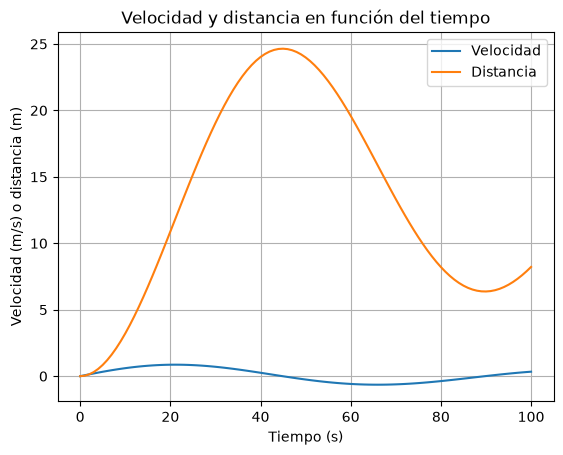

In [2]:
import numpy as np
import matplotlib.pyplot as plt

datos = np.loadtxt("velocidades.txt")

tiempo = datos[:, 0]
velocidad = datos[:, 1]

distancia = np.zeros(len(tiempo))

for i in range(1, len(tiempo)):
    dt = tiempo[i] - tiempo[i - 1]
    distancia[i] = distancia[i - 1] + (velocidad[i] + velocidad[i - 1]) * dt / 2

plt.plot(tiempo, velocidad, label="Velocidad")
plt.plot(tiempo, distancia, label="Distancia")

plt.xlabel("Tiempo (s)")
plt.ylabel("Velocidad (m/s) o distancia (m)")
plt.title("Velocidad y distancia en función del tiempo")
plt.legend()
plt.grid()

plt.show()

## Ejercicio 2: Límite de difracción de un telescopio
Funciones de Bessel usando regla de Simpson y comparación con SciPy.

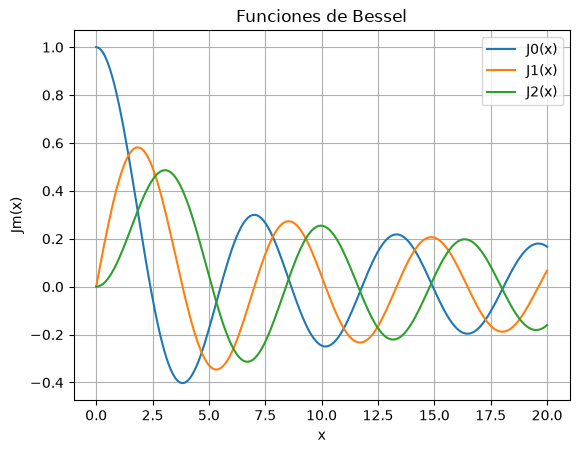

In [3]:
import numpy as np
import matplotlib.pyplot as plt

def J(m, x):
    N = 1000
    a = 0
    b = np.pi
    h = (b - a) / N

    suma = 0

    for i in range(1, N):
        theta = a + i * h
        f = np.cos(m * theta - x * np.sin(theta))

        if i % 2 == 0:
            suma = suma + 2 * f
        else:
            suma = suma + 4 * f

    f0 = np.cos(m * a - x * np.sin(a))
    fN = np.cos(m * b - x * np.sin(b))

    integral = (h / 3) * (f0 + suma + fN)

    return integral / np.pi


x = np.linspace(0, 20, 200)

J0 = []
J1 = []
J2 = []

for valor in x:
    J0.append(J(0, valor))
    J1.append(J(1, valor))
    J2.append(J(2, valor))

plt.plot(x, J0, label="J0(x)")
plt.plot(x, J1, label="J1(x)")
plt.plot(x, J2, label="J2(x)")

plt.xlabel("x")
plt.ylabel("Jm(x)")
plt.title("Funciones de Bessel")
plt.legend()
plt.grid()

plt.show()


Diferencia máxima para J 0 : 1.4432899320127035e-15
Diferencia máxima para J 1 : 1.609823385706477e-15
Diferencia máxima para J 2 : 9.43689570931383e-16


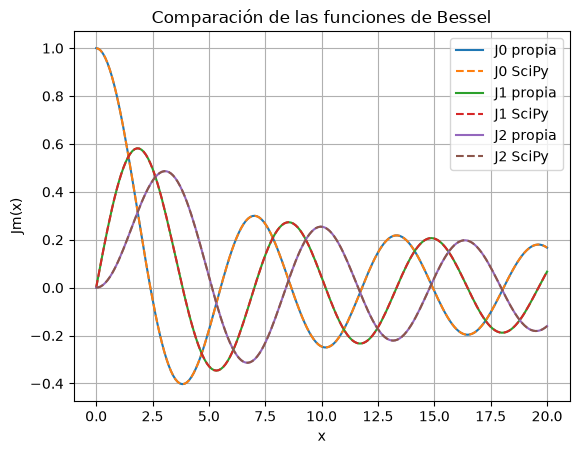

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import simpson

def J_scipy(m, x):
    N = 1000
    theta = np.linspace(0, np.pi, N + 1)

    f = np.cos(m * theta - x * np.sin(theta))

    integral = simpson(f, x=theta)

    return integral / np.pi


x = np.linspace(0, 20, 200)

for m in range(3):

    valores_propios = []
    valores_scipy = []

    for valor in x:
        valores_propios.append(J(m, valor))
        valores_scipy.append(J_scipy(m, valor))

    plt.plot(x, valores_propios, label="J" + str(m) + " propia")
    plt.plot(x, valores_scipy, "--", label="J" + str(m) + " SciPy")

    diferencia = np.max(np.abs(
        np.array(valores_propios) - np.array(valores_scipy)
    ))

    print("Diferencia máxima para J", m, ":", diferencia)

plt.xlabel("x")
plt.ylabel("Jm(x)")
plt.title("Comparación de las funciones de Bessel")
plt.legend()
plt.grid()

plt.show()

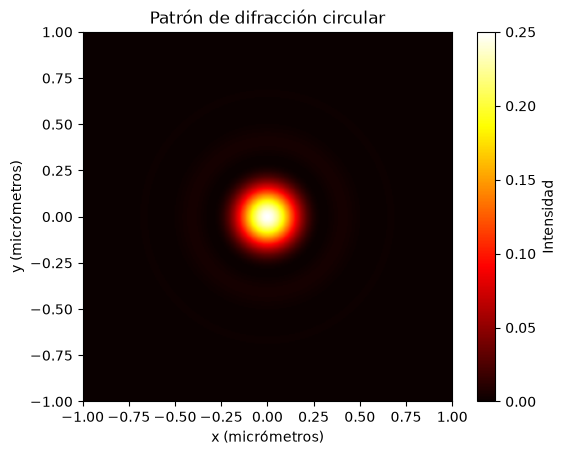

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import j1

lam = 500e-9
k = 2 * np.pi / lam

N = 301

x = np.linspace(-1e-6, 1e-6, N)
y = np.linspace(-1e-6, 1e-6, N)

X, Y = np.meshgrid(x, y)

r = np.sqrt(X**2 + Y**2)

kr = k * r

cociente = np.ones_like(r) * 0.5

mascara = kr != 0

cociente[mascara] = j1(kr[mascara]) / kr[mascara]

intensidad = cociente**2

plt.imshow(
    intensidad,
    extent=[-1, 1, -1, 1],
    origin="lower",
    cmap="hot"
)

plt.xlabel("x (micrómetros)")
plt.ylabel("y (micrómetros)")
plt.title("Patrón de difracción circular")
plt.colorbar(label="Intensidad")

plt.show()

## Ejercicio 3: Capacidad calorífica de un sólido (Debye)

In [10]:

import numpy as np
import matplotlib.pyplot as plt

# Datos del aluminio
V = 1.0e-3
rho = 6.022e28
kB = 1.380649e-23
thetaD = 428

# Funcion para calcular la capacidad calorifica
def Cv(T):
    N = 50

    # Puntos y pesos de Gauss entre -1 y 1
    puntos, pesos = np.polynomial.legendre.leggauss(N)

    # Limites de integracion
    a = 0
    b = thetaD / T

    # Cambio de intervalo de -1,1 a 0,b
    x = (b - a) * puntos / 2 + (b + a) / 2

    # Funcion que se va a integrar
    f = x**4 * np.exp(x) / (np.exp(x) - 1)**2

    # Cuadratura gaussiana
    integral = (b - a) / 2 * np.sum(pesos * f)

    # Capacidad calorifica
    capacidad = 9 * V * rho * kB * (T / thetaD)**3 * integral

    return capacidad

# Ejemplo: capacidad calorifica a 300 K
print("Capacidad calorifica a 300 K:", Cv(300), "J/K")



Capacidad calorifica a 300 K: 2257.797304945592 J/K


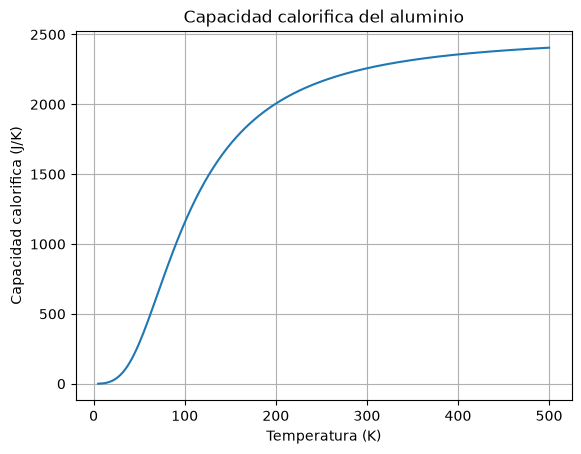

In [11]:

# Temperaturas desde 5 K hasta 500 K
temperaturas = np.linspace(5, 500, 200)

# Calcular la capacidad calorifica para cada temperatura
capacidades = []

for T in temperaturas:
    capacidades.append(Cv(T))

# Graficar
plt.plot(temperaturas, capacidades)

plt.xlabel("Temperatura (K)")
plt.ylabel("Capacidad calorifica (J/K)")
plt.title("Capacidad calorifica del aluminio")
plt.grid()
plt.show()


## Ejercicio 4: Oscilador armónico cuántico

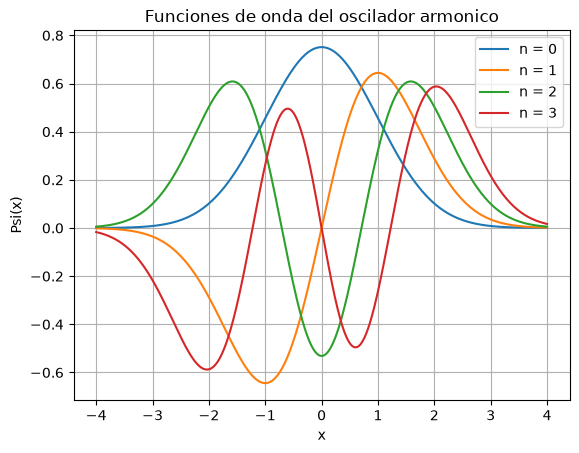

In [12]:

import numpy as np
import matplotlib.pyplot as plt
import math

# Funcion para calcular los polinomios de Hermite
def H(n, x):
    if n == 0:
        return np.ones_like(x)
    elif n == 1:
        return 2 * x
    else:
        H0 = np.ones_like(x)
        H1 = 2 * x

        for m in range(1, n):
            H2 = 2 * x * H1 - 2 * m * H0
            H0 = H1
            H1 = H2

        return H1

# Funcion de onda
def psi(n, x):
    factor = 1 / np.sqrt((2**n) * math.factorial(n) * np.sqrt(np.pi))
    return factor * np.exp(-x**2 / 2) * H(n, x)

# Valores de x entre -4 y 4
x = np.linspace(-4, 4, 500)

# Graficar las funciones de onda
for n in range(4):
    plt.plot(x, psi(n, x), label="n = " + str(n))

plt.xlabel("x")
plt.ylabel("Psi(x)")
plt.title("Funciones de onda del oscilador armonico")
plt.legend()
plt.grid()
plt.show()



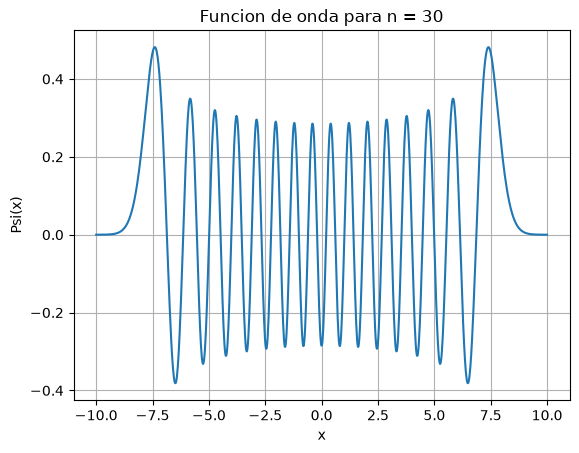

In [13]:

# Valores de x entre -10 y 10
x = np.linspace(-10, 10, 1000)

# Funcion de onda para n = 30
y = psi(30, x)

plt.plot(x, y)
plt.xlabel("x")
plt.ylabel("Psi(x)")
plt.title("Funcion de onda para n = 30")
plt.grid()
plt.show()


In [14]:

# Cuadratura gaussiana para n = 5
n = 5
N = 100

# Puntos y pesos de Gauss-Hermite
puntos, pesos = np.polynomial.hermite.hermgauss(N)

# Funcion de onda sin el factor exponencial
factor = 1 / np.sqrt((2**n) * math.factorial(n) * np.sqrt(np.pi))
polinomio = H(n, puntos)

# Integral de x^2 por el cuadrado de la funcion de onda
integrando = puntos**2 * (factor * polinomio)**2

# Cuadratura de Gauss-Hermite
media_cuadratica = np.sum(pesos * integrando)

# Incertidumbre de posicion
incertidumbre = np.sqrt(media_cuadratica)

print("Valor de <x^2> =", media_cuadratica)
print("Incertidumbre de posicion =", incertidumbre)


Valor de <x^2> = 5.4999999999999964
Incertidumbre de posicion = 2.345207879911714


## Ejercicio 5: Atracción gravitacional de una lámina uniforme

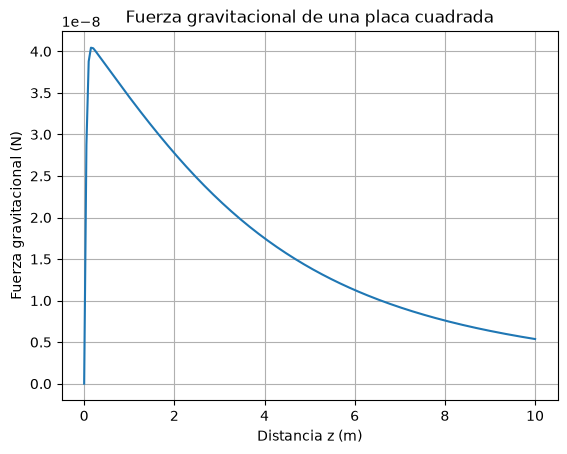

In [15]:

import numpy as np
import matplotlib.pyplot as plt

# Datos del problema
G = 6.674e-11
M = 10000
m = 1
L = 10
sigma = M / L**2

# Cuadratura gaussiana
N = 100
puntos, pesos = np.polynomial.legendre.leggauss(N)

# Transformar los puntos al intervalo [-L/2, L/2]
x = (L / 2) * puntos
y = (L / 2) * puntos

# Funcion para calcular la fuerza gravitacional
def fuerza(z):
    suma = 0

    for i in range(N):
        for j in range(N):
            denominador = (x[i]**2 + y[j]**2 + z**2)**(3/2)
            suma = suma + pesos[i] * pesos[j] / denominador

    integral = (L / 2)**2 * suma
    F = G * m * sigma * z * integral

    return F

# Distancias entre 0 y 10 metros
z_valores = np.linspace(0, 10, 200)

# Calcular la fuerza para cada distancia
F_valores = []

for z in z_valores:
    F_valores.append(fuerza(z))

# Graficar
plt.plot(z_valores, F_valores)
plt.xlabel("Distancia z (m)")
plt.ylabel("Fuerza gravitacional (N)")
plt.title("Fuerza gravitacional de una placa cuadrada")
plt.grid()
plt.show()


## Ejercicio 6: Rejillas de difracción

In [ ]:
# Tu código aquí


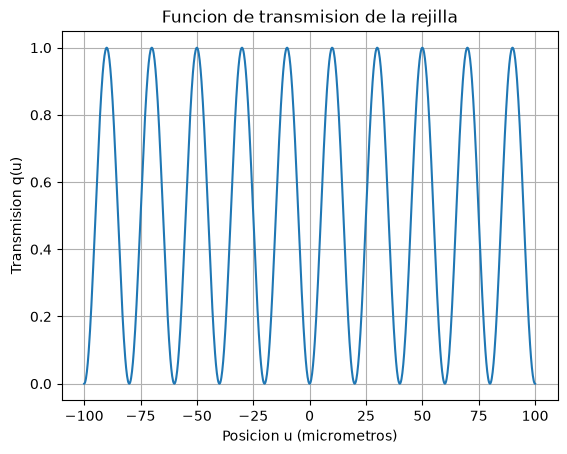

In [17]:

import numpy as np
import matplotlib.pyplot as plt

# Separacion entre rendijas
d = 20e-6

# Calcular alpha
alpha = np.pi / d

# Funcion de transmision
def q(u):
    return np.sin(alpha * u)**2

# Graficar la funcion de transmision
u = np.linspace(-100e-6, 100e-6, 1000)

plt.plot(u * 1e6, q(u))
plt.xlabel("Posicion u (micrometros)")
plt.ylabel("Transmision q(u)")
plt.title("Funcion de transmision de la rejilla")
plt.grid()
plt.show()


In [18]:

import numpy as np
import matplotlib.pyplot as plt

# Datos del problema
lam = 500e-9
f = 1.0
d = 20e-6
alpha = np.pi / d
w = 10 * d

# Funcion de transmision
def q(u):
    return np.sin(alpha * u)**2

# Puntos para integrar sobre la rejilla
N = 10001
u = np.linspace(-w/2, w/2, N)
transmision = q(u)

# Posiciones de la pantalla
x = np.linspace(-0.05, 0.05, 1001)

# Calcular la intensidad
I = []

for posicion in x:
    integrando = transmision * np.exp(
        2j * np.pi * posicion * u / (lam * f)
    )

    amplitud = np.trapz(integrando, u)
    intensidad = abs(amplitud)**2

    I.append(intensidad)

I = np.array(I)

# Normalizar la intensidad para facilitar la grafica
I = I / np.max(I)

plt.plot(x * 100, I)
plt.xlabel("Posicion en la pantalla (cm)")
plt.ylabel("Intensidad normalizada")
plt.title("Patron de difraccion de diez rendijas")
plt.grid()
plt.show()


AttributeError: module 'numpy' has no attribute 'trapz'

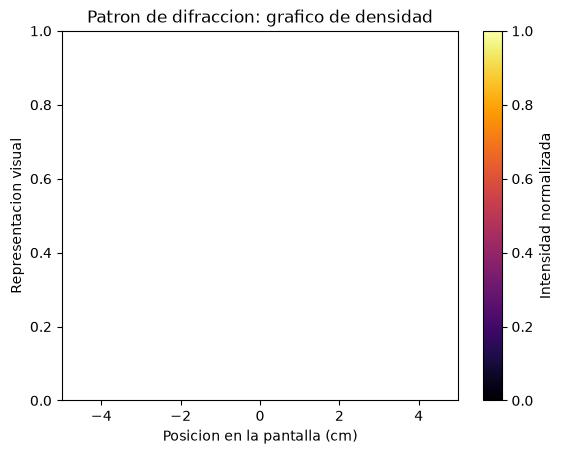

In [19]:

# Crear una matriz con filas identicas de intensidad
imagen = np.tile(I, (100, 1))

plt.imshow(
    imagen,
    extent=[x[0] * 100, x[-1] * 100, 0, 1],
    aspect="auto",
    origin="lower",
    cmap="inferno"
)

plt.xlabel("Posicion en la pantalla (cm)")
plt.ylabel("Representacion visual")
plt.title("Patron de difraccion: grafico de densidad")
plt.colorbar(label="Intensidad normalizada")
plt.show()
